# Phase 16 — Consistent Model Comparison & Final Evaluation

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Correct the Phase 15 comparison issue and create one consistent, auditable comparison of every candidate model from Phase 14, using the exact same held-out test observations. This notebook evaluates the saved Phase 14 predictions and saved metrics; it does not silently retrain models or invent missing predictions.

**Important:** If Phase 14 saved predictions only for the selected model, this notebook will report that full model-by-model test comparison is unavailable from the saved artifacts. In that case, it will use validation results for model selection evidence and recommend a controlled rerun that exports test predictions for every candidate.

## 1. Setup and locate Phase 14/15 artifacts

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

PRED_REL = Path("data/processed/corrected_model_predictions/asx_3m_corrected_test_predictions.csv")
METRICS_REL = Path("reports/corrected_model_training/corrected_test_baseline_comparison.csv")
VALID_REL = Path("reports/corrected_model_training/corrected_validation_comparison.csv")
SUMMARY_REL = Path("reports/corrected_model_training/phase14_corrected_model_summary.json")
REPORT_REL = Path("reports/model_interpretation/phase15_model_interpretation_report.md")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / PRED_REL).exists():
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and (p / PRED_REL).exists():
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find Phase 14 corrected test predictions. Run Phase 14 first.")

PRED_PATH = PROJECT_ROOT / PRED_REL
METRICS_PATH = PROJECT_ROOT / METRICS_REL
VALID_PATH = PROJECT_ROOT / VALID_REL
SUMMARY_PATH = PROJECT_ROOT / SUMMARY_REL
REPORT_PATH = PROJECT_ROOT / REPORT_REL
OUT = PROJECT_ROOT / "reports" / "final_model_evaluation"
OUT.mkdir(parents=True, exist_ok=True)

for p in [PRED_PATH, METRICS_PATH, VALID_PATH, SUMMARY_PATH, REPORT_PATH]:
    print(p.name, "exists:", p.exists())

asx_3m_corrected_test_predictions.csv exists: True
corrected_test_baseline_comparison.csv exists: True
corrected_validation_comparison.csv exists: True
phase14_corrected_model_summary.json exists: True
phase15_model_interpretation_report.md exists: True


## 2. Load artifacts and normalize column names

Column names are normalized to lowercase to avoid issues caused by capitalization differences. The notebook records the original column names for auditability.

In [2]:
def load_csv_if_exists(path):
    if not path.exists():
        return pd.DataFrame()
    return pd.read_csv(path, low_memory=False)

raw_metrics = load_csv_if_exists(METRICS_PATH)
raw_validation = load_csv_if_exists(VALID_PATH)
pred = load_csv_if_exists(PRED_PATH)
if SUMMARY_PATH.exists():
    phase14_summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
else:
    phase14_summary = {}

print("Original test-metrics columns:", raw_metrics.columns.tolist())
print("Original validation columns:", raw_validation.columns.tolist())
print("Original prediction columns:", pred.columns.tolist())

metrics = raw_metrics.copy()
metrics.columns = [str(c).strip().lower() for c in metrics.columns]
validation = raw_validation.copy()
validation.columns = [str(c).strip().lower() for c in validation.columns]
pred.columns = [str(c).strip().lower() for c in pred.columns]

display(metrics)
display(validation)

Original test-metrics columns: ['model', 'n', 'MAE', 'RMSE', 'R2', 'actual_mean', 'predicted_mean', 'mean_prediction_bias']
Original validation columns: ['model', 'n', 'MAE', 'RMSE', 'R2', 'actual_mean', 'predicted_mean', 'mean_prediction_bias']
Original prediction columns: ['ticker', 'date', 'target_endpoint_date_3m', 'forward_return_3m', 'predicted_forward_return_3m', 'prediction_error']


,model,n,mae,rmse,r2,actual_mean,predicted_mean,mean_prediction_bias
0,Train+validation mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362
1,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


,model,n,mae,rmse,r2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,6084,0.141984,0.195113,-0.081749,0.075098,0.021461,-0.053637
1,HistGradientBoosting,6084,0.142511,0.198628,-0.121080,0.075098,0.027535,-0.047563
2,Random Forest,6084,0.146571,0.204790,-0.191712,0.075098,0.030853,-0.044245
3,Ridge Regression,6084,0.147386,0.202863,-0.169392,0.075098,0.011043,-0.064055
4,Linear Regression,6084,0.147392,0.202870,-0.169472,0.075098,0.011037,-0.064061


## 3. Repair the baseline comparison logic

The previous report's baseline parser may have failed because model names or column capitalization differed. Here we normalize both and print the rows before comparing. If the file contains only one row or does not include a baseline, we explicitly report that limitation.

In [3]:
baseline_assessment = {"status": "not assessed"}
if metrics.empty:
    baseline_assessment = {"status": "test comparison file missing"}
elif not {"model", "mae", "rmse", "r2"}.issubset(metrics.columns):
    baseline_assessment = {
        "status": "required metric columns missing",
        "available_columns": metrics.columns.tolist()
    }
else:
    metrics["model"] = metrics["model"].astype(str).str.strip()
    baseline_mask = metrics["model"].str.contains("baseline|dummy|mean", case=False, na=False)
    baseline_rows = metrics[baseline_mask]
    candidate_rows = metrics[~baseline_mask]

    if len(baseline_rows) >= 1 and len(candidate_rows) >= 1:
        baseline_row = baseline_rows.iloc[0]
        candidate_row = candidate_rows.iloc[0]
        baseline_assessment = {
            "baseline_model": baseline_row["model"],
            "candidate_model": candidate_row["model"],
            "baseline_mae": float(baseline_row["mae"]),
            "candidate_mae": float(candidate_row["mae"]),
            "mae_improvement_percent": float(
                100 * (baseline_row["mae"] - candidate_row["mae"]) / baseline_row["mae"]
            ) if baseline_row["mae"] > 0 else None,
            "baseline_rmse": float(baseline_row["rmse"]),
            "candidate_rmse": float(candidate_row["rmse"]),
            "baseline_r2": float(baseline_row["r2"]),
            "candidate_r2": float(candidate_row["r2"]),
            "candidate_beats_baseline_mae": bool(candidate_row["mae"] < baseline_row["mae"]),
            "note": "Only the first non-baseline row is compared here; see the full table for all saved rows."
        }
    else:
        baseline_assessment = {
            "status": "could not identify both baseline and non-baseline rows",
            "rows_found": metrics.to_dict(orient="records")
        }

print(json.dumps(baseline_assessment, indent=2, default=str))
with open(OUT / "repaired_baseline_assessment.json", "w", encoding="utf-8") as f:
    json.dump(baseline_assessment, f, indent=2, default=str)

{
  "status": "could not identify both baseline and non-baseline rows",
  "rows_found": [
    {
      "model": "Train+validation mean baseline",
      "n": 9412,
      "mae": 0.143784486091985,
      "rmse": 0.1849644945838032,
      "r2": -0.0449496718904638,
      "actual_mean": -0.009887806217044,
      "predicted_mean": 0.0284744327304448,
      "mean_prediction_bias": 0.0383622389474888
    },
    {
      "model": "Training mean baseline",
      "n": 9412,
      "mae": 0.143784486091985,
      "rmse": 0.1849644945838032,
      "r2": -0.0449496718904638,
      "actual_mean": -0.009887806217044,
      "predicted_mean": 0.0284744327304448,
      "mean_prediction_bias": 0.0383622389474888
    }
  ]
}


## 4. Recalculate the selected-model test metrics

The saved prediction file contains only the model selected in Phase 14. Recalculate its test metrics directly from predictions so they do not depend on copied summary values.

In [4]:
required_prediction_cols = {"forward_return_3m", "predicted_forward_return_3m"}
if not required_prediction_cols.issubset(pred.columns):
    raise ValueError(f"Prediction file is missing: {sorted(required_prediction_cols - set(pred.columns))}")

pred["forward_return_3m"] = pd.to_numeric(pred["forward_return_3m"], errors="coerce")
pred["predicted_forward_return_3m"] = pd.to_numeric(pred["predicted_forward_return_3m"], errors="coerce")
eval_pred = pred.dropna(subset=["forward_return_3m", "predicted_forward_return_3m"]).copy()
y = eval_pred["forward_return_3m"].astype(float).to_numpy()
yhat = eval_pred["predicted_forward_return_3m"].astype(float).to_numpy()

selected_metrics = {
    "model": phase14_summary.get("selected_model_by_validation_mae", "unknown"),
    "n": int(len(y)),
    "mae": float(mean_absolute_error(y, yhat)),
    "rmse": float(np.sqrt(mean_squared_error(y, yhat))),
    "r2": float(r2_score(y, yhat)) if len(y) > 1 else np.nan,
    "actual_mean": float(np.mean(y)),
    "predicted_mean": float(np.mean(yhat)),
    "mean_prediction_bias": float(np.mean(yhat) - np.mean(y))
}
display(pd.DataFrame([selected_metrics]))
pd.DataFrame([selected_metrics]).to_csv(OUT / "selected_model_recalculated_metrics.csv", index=False)

,model,n,mae,rmse,r2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


## 5. Compare validation performance across candidates

The validation table is the correct place to compare all models if it contains a row per model. Do not use the test set repeatedly to choose models.

,model,n,mae,rmse,r2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,6084,0.141984,0.195113,-0.081749,0.075098,0.021461,-0.053637
1,HistGradientBoosting,6084,0.142511,0.198628,-0.121080,0.075098,0.027535,-0.047563
2,Random Forest,6084,0.146571,0.204790,-0.191712,0.075098,0.030853,-0.044245
3,Ridge Regression,6084,0.147386,0.202863,-0.169392,0.075098,0.011043,-0.064055
4,Linear Regression,6084,0.147392,0.202870,-0.169472,0.075098,0.011037,-0.064061


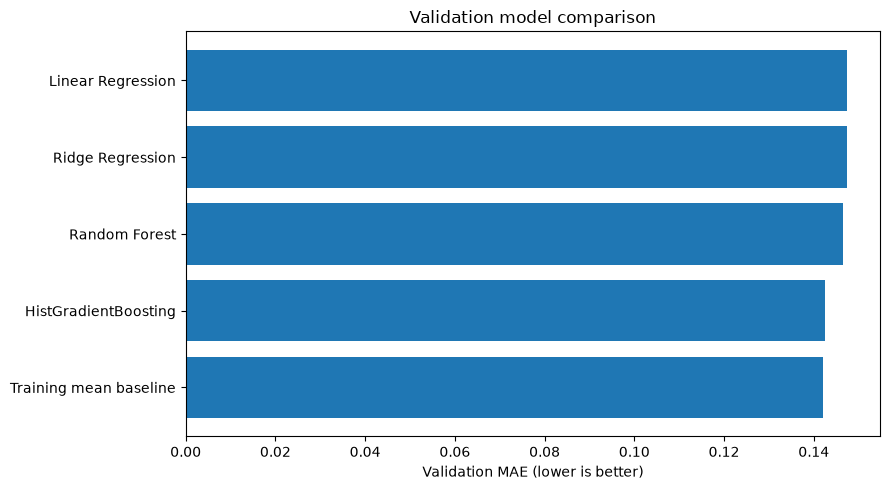

Best validation MAE row: {'model': 'Training mean baseline', 'n': 6084, 'mae': 0.1419844395510397, 'rmse': 0.1951126199363147, 'r2': -0.0817491867381234, 'actual_mean': 0.0750982385460774, 'predicted_mean': 0.0214613233630676, 'mean_prediction_bias': -0.0536369151830098}


In [5]:
if validation.empty:
    print("Validation comparison file is missing.")
else:
    display(validation)
    required_val = {"model", "mae", "rmse", "r2"}
    if required_val.issubset(validation.columns):
        validation_sorted = validation.sort_values("mae").reset_index(drop=True)
        validation_sorted.to_csv(OUT / "validation_comparison_sorted.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 5))
        plot_data = validation_sorted.sort_values("mae", ascending=True)
        ax.barh(plot_data["model"].astype(str), plot_data["mae"].astype(float))
        ax.set_xlabel("Validation MAE (lower is better)")
        ax.set_title("Validation model comparison")
        plt.tight_layout()
        plt.savefig(OUT / "validation_mae_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
        print("Best validation MAE row:", validation_sorted.iloc[0].to_dict())
    else:
        print("Validation metrics do not have the expected model/MAE/RMSE/R² columns.")

## 6. Check whether full candidate test predictions were saved

A valid test comparison of every candidate requires predictions from each model on the exact same test rows. If the saved file only contains one prediction column, this phase will not fabricate missing model predictions. The correct remedy is to rerun Phase 14 with an export loop that saves every candidate's test predictions.

In [6]:
prediction_columns = [
    c for c in pred.columns
    if c.startswith("predicted_") and c != "prediction_error"
]
print("Prediction columns found:", prediction_columns)

if len(prediction_columns) <= 1:
    full_test_comparison_available = False
    print(
        "Only one model prediction series is available. "
        "A complete all-model test comparison cannot be reconstructed from this file alone."
    )
else:
    full_test_comparison_available = True
    comparison_rows = []
    for col in prediction_columns:
        actual_col = "forward_return_3m"
        subset = pred.dropna(subset=[actual_col, col])
        yt = subset[actual_col].astype(float)
        yp = subset[col].astype(float)
        comparison_rows.append({
            "model": col.replace("predicted_", ""),
            "n": len(subset),
            "mae": mean_absolute_error(yt, yp),
            "rmse": np.sqrt(mean_squared_error(yt, yp)),
            "r2": r2_score(yt, yp) if len(subset) > 1 else np.nan,
            "actual_mean": yt.mean(),
            "predicted_mean": yp.mean()
        })
    test_comparison = pd.DataFrame(comparison_rows).sort_values("mae")
    display(test_comparison)
    test_comparison.to_csv(OUT / "all_model_test_comparison.csv", index=False)

Prediction columns found: ['predicted_forward_return_3m']
Only one model prediction series is available. A complete all-model test comparison cannot be reconstructed from this file alone.


## 7. Create a transparent conclusion

This report separates what the saved artifacts establish from what is still missing.

In [7]:
if validation.empty:
    validation_statement = "Validation comparison unavailable in saved artifacts."
elif {"model", "mae"}.issubset(validation.columns):
    validation_sorted = validation.sort_values("mae")
    validation_statement = (
        f"Best validation MAE model: {validation_sorted.iloc[0]['model']} "
        f"(MAE={float(validation_sorted.iloc[0]['mae']):.6f})."
    )
else:
    validation_statement = "Validation file exists but required columns were not recognized."

if full_test_comparison_available:
    test_statement = "Multiple prediction series were found; an all-model test comparison was saved."
else:
    test_statement = (
        "Only the selected model's test predictions were found. "
        "Do not claim that every candidate model was compared on the test set."
    )

conclusion = {
    "phase": 16,
    "selected_model_from_phase14": phase14_summary.get("selected_model_by_validation_mae"),
    "selected_model_test_metrics": selected_metrics,
    "baseline_assessment": baseline_assessment,
    "validation_summary": validation_statement,
    "full_candidate_test_comparison_available": full_test_comparison_available,
    "test_comparison_status": test_statement,
    "recommendation": (
        "If the selected model does not beat the mean baseline, report the result honestly. "
        "For a complete final comparison, rerun Phase 14 with all candidate test predictions saved."
    )
}
with open(OUT / "phase16_final_evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(conclusion, f, indent=2, default=str)

report_lines = [
    "# Phase 16 — Final Model Evaluation",
    "",
    "## Selected model test metrics",
    f"- Model: {selected_metrics['model']}",
    f"- Test rows: {selected_metrics['n']}",
    f"- MAE: {selected_metrics['mae']:.6f}",
    f"- RMSE: {selected_metrics['rmse']:.6f}",
    f"- R²: {selected_metrics['r2']:.6f}",
    f"- Actual mean return: {selected_metrics['actual_mean']:.6f}",
    f"- Predicted mean return: {selected_metrics['predicted_mean']:.6f}",
    f"- Mean prediction bias: {selected_metrics['mean_prediction_bias']:.6f}",
    "",
    "## Validation comparison",
    validation_statement,
    "",
    "## Test comparison availability",
    test_statement,
    "",
    "## Baseline assessment",
    json.dumps(baseline_assessment, indent=2, default=str),
    "",
    "## Limitations",
    "- A regression score does not establish trading profitability.",
    "- The selected-model prediction file alone cannot reconstruct predictions from models that were not saved.",
    "- Features must be checked for point-in-time availability and target leakage.",
    "- Results describe the historical test period only; they do not guarantee future performance."
]
report_path = OUT / "phase16_final_model_evaluation_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(json.dumps(conclusion, indent=2, default=str))
print("\nReport saved:", report_path)

{
  "phase": 16,
  "selected_model_from_phase14": "Training mean baseline",
  "selected_model_test_metrics": {
    "model": "Training mean baseline",
    "n": 9412,
    "mae": 0.14378448609198502,
    "rmse": 0.18496449458380324,
    "r2": -0.044949671890463616,
    "actual_mean": -0.009887806217044012,
    "predicted_mean": 0.028474432730444803,
    "mean_prediction_bias": 0.038362238947488816
  },
  "baseline_assessment": {
    "status": "could not identify both baseline and non-baseline rows",
    "rows_found": [
      {
        "model": "Train+validation mean baseline",
        "n": 9412,
        "mae": 0.143784486091985,
        "rmse": 0.1849644945838032,
        "r2": -0.0449496718904638,
        "actual_mean": -0.009887806217044,
        "predicted_mean": 0.0284744327304448,
        "mean_prediction_bias": 0.0383622389474888
      },
      {
        "model": "Training mean baseline",
        "n": 9412,
        "mae": 0.143784486091985,
        "rmse": 0.1849644945838032,
      

## 8. Completion checklist

- Confirm the validation comparison includes all candidate models.
- Confirm the saved test prediction file covers the same observations for each model if making an all-model test comparison.
- If only one prediction series exists, rerun Phase 14 to export all candidate test predictions.
- Record whether the selected model beats the training+validation mean baseline.
- Do not claim investment profitability without a separate realistic backtest including transaction costs and execution assumptions.